# Assignment 4: LSTM text generation on the Epicurious Recipes dataset

Adapted from Foster, *Generative Deep Learning* (2nd ed.), `notebooks/05_autoregressive/01_lstm/lstm.ipynb`.

**Steps**
1. Load the Epicurious recipes (Kaggle) and keep the title + directions of each recipe.
2. **Clean up and tokenize**: pad punctuation so it becomes separate "words", lower-case, and map the 10,000 most
   common words to integers.
3. **Train** an LSTM to predict the next word at every position (input = words 1..n, target = words 2..n+1).
4. **Generate** long text autoregressively: feed a sequence of words, sample the next word, append it, repeat.
5. Compare the output for **two temperatures, 0.5 and 1.5** (the assignment excludes 1.0 and 0.2).

Small changes so it runs on current Colab / Keras 3: `kagglehub` download, `.keras` / `.weights.h5` save formats,
faster prediction inside the generation loop.

> Runtime: **Runtime ▸ Change runtime type ▸ GPU (T4)**.

In [1]:
import os, glob, json, re, string
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, losses

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
SMOKE_TEST = bool(os.environ.get("LSTM_SMOKE"))  # only for a quick offline test with fake data
os.makedirs("models", exist_ok=True); os.makedirs("checkpoint", exist_ok=True)

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 0. Parameters

In [2]:
VOCAB_SIZE = 10000
MAX_LEN = 200
EMBEDDING_DIM = 100
N_UNITS = 128
SEED = 42
BATCH_SIZE = 32
EPOCHS = 25
TEMPERATURES = [0.5, 1.5]   # the two temperatures used for the submission (not 1.0 or 0.2)
if SMOKE_TEST:
    EPOCHS, VOCAB_SIZE = 1, 500
np.random.seed(SEED); tf.random.set_seed(SEED)

## 1. Load the data

In [3]:
if SMOKE_TEST:
    recipe_data = [{"title": f"Test dish {i}", "directions": ["Preheat oven to 350°F.", "Mix flour, sugar and eggs; bake 20 minutes."]}
                   for i in range(200)] + [{"title": None, "directions": None}]
else:
    import kagglehub
    path = kagglehub.dataset_download("hugodarwood/epirecipes")
    json_path = glob.glob(os.path.join(path, "**", "full_format_recipes.json"), recursive=True)[0]
    with open(json_path) as f:
        recipe_data = json.load(f)
print(f"{len(recipe_data):,} raw records")

Using Colab cache for faster access to the 'epirecipes' dataset.
20,130 raw records


In [4]:
# Keep only recipes that have a title and directions; one string per recipe
filtered_data = [
    "Recipe for " + x["title"] + " | " + " ".join(x["directions"])
    for x in recipe_data
    if "title" in x and x["title"] is not None and "directions" in x and x["directions"] is not None
]
n_recipes = len(filtered_data)
print(f"{n_recipes:,} recipes loaded")
print(filtered_data[9])

20,111 recipes loaded
Recipe for Ham Persillade with Mustard Potato Salad and Mashed Peas  | Chop enough parsley leaves to measure 1 tablespoon; reserve. Chop remaining leaves and stems and simmer with broth and garlic in a small saucepan, covered, 5 minutes. Meanwhile, sprinkle gelatin over water in a medium bowl and let soften 1 minute. Strain broth through a fine-mesh sieve into bowl with gelatin and stir to dissolve. Season with salt and pepper. Set bowl in an ice bath and cool to room temperature, stirring. Toss ham with reserved parsley and divide among jars. Pour gelatin on top and chill until set, at least 1 hour. Whisk together mayonnaise, mustard, vinegar, 1/4 teaspoon salt, and 1/4 teaspoon pepper in a large bowl. Stir in celery, cornichons, and potatoes. Pulse peas with marjoram, oil, 1/2 teaspoon pepper, and 1/4 teaspoon salt in a food processor to a coarse mash. Layer peas, then potato salad, over ham.


## 2. Clean up and tokenize the text

In [5]:
# Pad punctuation with spaces so that '.', ',', '(' etc. become separate tokens
def pad_punctuation(s):
    s = re.sub(f"([{string.punctuation}])", r" \1 ", s)
    s = re.sub(" +", " ", s)
    return s


text_data = [pad_punctuation(x) for x in filtered_data]
print(text_data[9])

Recipe for Ham Persillade with Mustard Potato Salad and Mashed Peas | Chop enough parsley leaves to measure 1 tablespoon ; reserve . Chop remaining leaves and stems and simmer with broth and garlic in a small saucepan , covered , 5 minutes . Meanwhile , sprinkle gelatin over water in a medium bowl and let soften 1 minute . Strain broth through a fine - mesh sieve into bowl with gelatin and stir to dissolve . Season with salt and pepper . Set bowl in an ice bath and cool to room temperature , stirring . Toss ham with reserved parsley and divide among jars . Pour gelatin on top and chill until set , at least 1 hour . Whisk together mayonnaise , mustard , vinegar , 1 / 4 teaspoon salt , and 1 / 4 teaspoon pepper in a large bowl . Stir in celery , cornichons , and potatoes . Pulse peas with marjoram , oil , 1 / 2 teaspoon pepper , and 1 / 4 teaspoon salt in a food processor to a coarse mash . Layer peas , then potato salad , over ham . 


In [6]:
text_ds = tf.data.Dataset.from_tensor_slices(text_data).batch(BATCH_SIZE).shuffle(1000, seed=SEED)

# Lower-case, keep the 10,000 most common tokens, pad / truncate every recipe to MAX_LEN + 1 tokens
vectorize_layer = layers.TextVectorization(
    standardize="lower", max_tokens=VOCAB_SIZE, output_mode="int", output_sequence_length=MAX_LEN + 1,
)
vectorize_layer.adapt(text_ds)
vocab = vectorize_layer.get_vocabulary()
VOCAB_SIZE = len(vocab)   # = 10,000 on the full dataset

for i, word in enumerate(vocab[:10]):
    print(f"{i}: {word}")
print("\nExample recipe as token ids:\n", vectorize_layer(text_data[9]).numpy())

0: 
1: [UNK]
2: .
3: ,
4: and
5: to
6: in
7: the
8: with
9: a

Example recipe as token ids:
 [  26   16  557    1    8  298  335  189    4 1054  494   27  332  228
  235  262    5  594   11  133   22  311    2  332   45  262    4  671
    4   70    8  171    4   81    6    9   65   80    3  121    3   59
   12    2  299    3   88  650   20   39    6    9   29   21    4   67
  529   11  164    2  320  171  102    9  374   13  643  306   25   21
    8  650    4   42    5  931    2   63    8   24    4   33    2  114
   21    6  178  181 1245    4   60    5  140  112    3   48    2  117
  557    8  285  235    4  200  292  980    2  107  650   28   72    4
  108   10  114    3   57  204   11  172    2   73  110  482    3  298
    3  190    3   11   23   32  142   24    3    4   11   23   32  142
   33    6    9   30   21    2   42    6  353    3 3224    3    4  150
    2  437  494    8 1281    3   37    3   11   23   15  142   33    3
    4   11   23   32  142   24    6    9  291  188    5

## 3. Create the training set (input = text, target = same text shifted by one word)

In [7]:
def prepare_inputs(text):
    text = tf.expand_dims(text, -1)
    tokenized = vectorize_layer(text)
    return tokenized[:, :-1], tokenized[:, 1:]


train_ds = text_ds.map(prepare_inputs).prefetch(tf.data.AUTOTUNE)

## 4. Build the LSTM

In [8]:
inputs = layers.Input(shape=(None,), dtype="int32")
x = layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM)(inputs)
x = layers.LSTM(N_UNITS, return_sequences=True)(x)
outputs = layers.Dense(VOCAB_SIZE, activation="softmax")(x)
lstm = models.Model(inputs, outputs)
lstm.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 100)      │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, None, 128)      │       117,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 10000)    │     1,290,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,407,248 (9.18 MB)

 Trainable params: 2,407,248 (9.18 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the LSTM

In [9]:
lstm.compile("adam", losses.SparseCategoricalCrossentropy())


class TextGenerator(callbacks.Callback):
    def __init__(self, index_to_word):
        super().__init__()
        self.index_to_word = index_to_word
        self.word_to_index = {word: index for index, word in enumerate(index_to_word)}

    def sample_from(self, probs, temperature):
        # temperature < 1 sharpens the distribution (safer words), > 1 flattens it (more surprising words)
        probs = np.asarray(probs, dtype="float64") ** (1 / temperature)
        probs = probs / np.sum(probs)
        return np.random.choice(len(probs), p=probs), probs

    def generate(self, start_prompt, max_tokens, temperature, verbose=True):
        start_tokens = [self.word_to_index.get(x, 1) for x in start_prompt.split()]
        sample_token = None
        info = []
        while len(start_tokens) < max_tokens and sample_token != 0:      # stop at max length or padding token
            y = self.model(np.array([start_tokens]), training=False).numpy()   # 1. feed the existing sequence
            sample_token, probs = self.sample_from(y[0][-1], temperature)       # 2. predict / sample the next word
            info.append({"prompt": start_prompt, "word_probs": probs})
            start_tokens.append(sample_token)                                   # 3. append it and repeat
            start_prompt = start_prompt + " " + self.index_to_word[sample_token]
        if verbose:
            print(f"\ngenerated text (temperature={temperature}):\n{start_prompt}\n")
        return info

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % 5 == 0 or epoch == 0:
            self.generate("recipe for", max_tokens=60, temperature=TEMPERATURES[0])


text_generator = TextGenerator(vocab)
checkpoint_cb = callbacks.ModelCheckpoint("./checkpoint/lstm.weights.h5", save_weights_only=True, verbose=0)

history = lstm.fit(train_ds, epochs=EPOCHS, callbacks=[checkpoint_cb, text_generator], verbose=2)

Epoch 1/25

generated text (temperature=0.5):
recipe for tomato all | preheat in a a high heat to the teaspoon stir , and salt , until tender . transfer to a bowl . cover , 1 / a large bowl . pour dish and salt . stir in a large a saucepan . transfer to a bowl . sauté heat until cooked is boiling , about

629/629 - 32s - 50ms/step - loss: 4.1597
Epoch 2/25
629/629 - 27s - 44ms/step - loss: 2.8813
Epoch 3/25
629/629 - 29s - 46ms/step - loss: 2.4467
Epoch 4/25
629/629 - 30s - 48ms/step - loss: 2.2247
Epoch 5/25

generated text (temperature=0.5):
recipe for [UNK] - style chicken | stir together all ingredients except the rum in a bowl until smooth . whisk in the remaining ingredients . cover and chill . let stand at room temperature for 30 minutes . in a large bowl , add the butter and cook , stirring occasionally , until the mixture is soft , about

629/629 - 33s - 52ms/step - loss: 2.0755
Epoch 6/25
629/629 - 31s - 49ms/step - loss: 1.9754
Epoch 7/25
629/629 - 31s - 50ms/step - loss: 1.

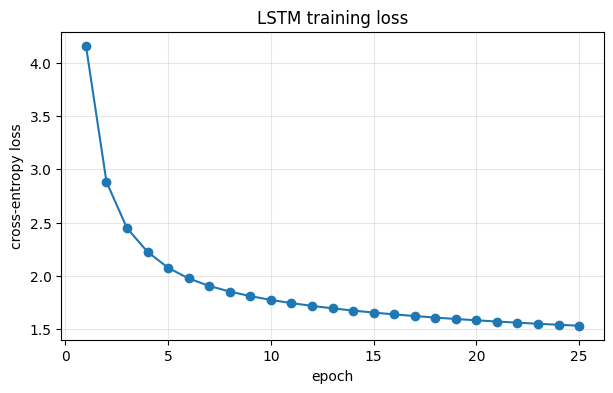

final loss = 1.532  (perplexity ~ 4.6)


In [10]:
lstm.save("./models/lstm.keras")
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(history.history["loss"]) + 1), history.history["loss"], marker="o")
plt.xlabel("epoch"); plt.ylabel("cross-entropy loss"); plt.title("LSTM training loss"); plt.grid(alpha=0.3)
plt.show()
print(f"final loss = {history.history['loss'][-1]:.3f}  (perplexity ~ {np.exp(history.history['loss'][-1]):.1f})")

## 6. Generate text at two temperatures

Each run feeds the network a starting sequence, samples the next word from the predicted distribution
(reshaped by the temperature), appends it, and repeats until 100 tokens or the end-of-text token.

In [11]:
def print_probs(info, vocab, top_k=5):
    for i in info:
        print(f"\nPROMPT: {i['prompt']}")
        word_probs = i["word_probs"]
        p_sorted = np.sort(word_probs)[::-1][:top_k]
        i_sorted = np.argsort(word_probs)[::-1][:top_k]
        for p, idx in zip(p_sorted, i_sorted):
            print(f"{vocab[idx]}:   \t{np.round(100 * p, 2)}%")
        print("--------")


PROMPTS = ["recipe for", "recipe for chocolate cake |", "recipe for grilled chicken with lemon |"]

In [17]:
# Wrap long generated text at 130 characters so it is readable here and not cut off in a PDF export
import builtins, textwrap
print = lambda *a, **k: builtins.print(*["\n".join(textwrap.fill(line, 130) for line in str(x).split("\n")) for x in a], **k)

### 6.1 Temperature = 0.5 (conservative)

In [18]:
np.random.seed(1)
T = TEMPERATURES[0]
for prompt in PROMPTS:
    text_generator.generate(prompt, max_tokens=100, temperature=T)


generated text (temperature=0.5):
recipe for roasted red - pepper and tomato salad | whisk first 4 ingredients in small bowl to blend . season dressing to taste
with salt and pepper . heat oil in large skillet over medium heat . add mushrooms , onions and onion and sauté until just
beginning to brown , about 5 minutes . add 1 / 2 cup broth , 1 / 2 cup broth , and remaining 1 / 2 cup broth . bring to boil .
reduce heat to medium - low ; simmer uncovered until liquid is absorbed , stirring occasionally , about 30


generated text (temperature=0.5):
recipe for chocolate cake | in a large saucepan bring the milk to a boil and slowly whisk in the sugar , the lemon juice , and the
mixture . in a bowl whisk together the cream , the sugar , the sugar , and the sugar and cook the mixture , stirring , for 3 to 4
minutes , or until it is thickened and the mixture is smooth and the mixture is smooth , in a colander set over a saucepan of
simmering water and cook the mixture , stirring occasionall

In [19]:
# Word-by-word probabilities after the temperature is applied (top 5 candidates at each step)
np.random.seed(10)
info = text_generator.generate("recipe for roasted vegetables | chop 1 /", max_tokens=10, temperature=TEMPERATURES[0])
print_probs(info, vocab)


generated text (temperature=0.5):
recipe for roasted vegetables | chop 1 / 4 -


PROMPT: recipe for roasted vegetables | chop 1 /
2:      49.63%
4:      35.05%
3:      13.06%
8:      2.22%
2cup:           0.01%
--------

PROMPT: recipe for roasted vegetables | chop 1 / 4
cup:    57.59%
inch:           16.61%
pound:          9.7%
of:     6.67%
pounds:         2.74%
--------


### 6.2 Temperature = 1.5 (adventurous)

In [20]:
np.random.seed(2)
T = TEMPERATURES[1]
for prompt in PROMPTS:
    text_generator.generate(prompt, max_tokens=100, temperature=T)


generated text (temperature=1.5):
recipe for braised with porcini corn ( scallops a sautéed white tomatoes | ) add fresh vegetables with bulgur ; nutmeg . combine
on heavy medium - high heat . add shrimp in skillet to coat , cover beans and cook at 105°f for intact , at least pan or 30
seconds , and pour drippings into bowl . add umeboshi quinoa ingredients to beets and mix on all of boursin - lined potatoes .
sprinkle peanuts over cheese . tightly peel almonds . melt remaining 4 tablespoons butter in endives , then 1 teaspoon coriander
and onions in parchment


generated text (temperature=1.5):
recipe for chocolate cake | stir passion bananas and whiskey - amaretto compote in margarita syrup . serve drinks over cold dish :
freeze 5 days in glasses for ice , or freeze . garnish each with if desired .


generated text (temperature=1.5):
recipe for grilled chicken with lemon | combine apple cider broths , through thinly whisk vigorously , grated part lemon , season
sage and add tablespo

In [21]:
# Word-by-word probabilities after the temperature is applied (top 5 candidates at each step)
np.random.seed(10)
info = text_generator.generate("recipe for roasted vegetables | chop 1 /", max_tokens=10, temperature=TEMPERATURES[1])
print_probs(info, vocab)


generated text (temperature=1.5):
recipe for roasted vegetables | chop 1 / bowls .


PROMPT: recipe for roasted vegetables | chop 1 /
2:      21.96%
4:      19.56%
3:      14.07%
8:      7.8%
2cup:           1.43%
--------

PROMPT: recipe for roasted vegetables | chop 1 / bowls
and:    45.48%
of:     8.45%
,:      7.79%
.:      3.94%
;:      2.94%
--------


In [22]:
# How 'peaked' is the next-word distribution at each temperature? (same prompt, same model)
y = lstm(np.array([[text_generator.word_to_index.get(w, 1) for w in "recipe for chocolate ice cream |".split()]]), training=False).numpy()[0][-1]
for T in TEMPERATURES:
    _, p = text_generator.sample_from(y, T)
    top = np.argsort(p)[::-1][:5]
    print(f"T={T}: top word '{vocab[top[0]]}' gets {100 * p[top[0]]:.1f}%, top-5 cover {100 * p[top].sum():.1f}%, "
          f"words needed for 90% of the probability: {int(np.searchsorted(np.cumsum(np.sort(p)[::-1]), 0.9)) + 1}")

T=0.5: top word 'in' gets 25.7%, top-5 cover 90.3%, words needed for 90% of the probability: 5
T=1.5: top word 'in' gets 6.0%, top-5 cover 26.5%, words needed for 90% of the probability: 242


## 7. Observations

**Training.** Over 25 epochs the cross-entropy loss fell from 4.16 to 1.53, a perplexity of about 4.6. In other words, the model is typically choosing between about 4 to 5 plausible next words. The samples printed during training show the progression: after 1 epoch the text was a jumble of cooking words, and by epoch 10 it already had the recipe format ("Recipe for ... | preheat oven to 450°F . heat 2 tablespoons oil ...").

**What temperature does.** The model outputs a probability for each of the 10,000 words. The temperature *T* reshapes that distribution before sampling (p^(1/T), then renormalised). For the prompt "recipe for chocolate ice cream |":

| | T = 0.5 | T = 1.5 |
|---|---|---|
| Probability of the most likely next word ("in") | 25.7% | 6.0% |
| Probability covered by the top 5 words | 90.3% | 26.5% |
| Number of words needed to cover 90% of the probability | 5 | 242 |

For "recipe for roasted vegetables | chop 1 /", the top choice "2" gets 49.6% at T = 0.5 but only 22.0% at T = 1.5.

**Temperature 0.5 (conservative).** The text reads like a real recipe: correct structure (title | steps), realistic quantities ("1 / 2 cup broth"), sensible cooking steps ("season dressing to taste with salt and pepper . heat oil in large skillet over medium heat"), and correct use of punctuation. The weaknesses are repetition and blandness. The chocolate-cake sample loops ("the sugar , the sugar , and the sugar", "the mixture is smooth and the mixture is smooth"), and the text drifts to the most common recipe patterns (the grilled-chicken prompt turned into "divide salad among 4 plates", then ended early with "and serve ."). Low temperature keeps choosing the few highest-probability words, so it is safe but predictable.

**Temperature 1.5 (adventurous).** The grammar and recipe "shape" survive (imperative verbs, quantities, full stops), but the content becomes incoherent: "cook at 105°F for intact", "melt remaining 4 tablespoons butter in endives", and a chocolate-cake recipe about "passion bananas and whiskey - amaretto compote in margarita syrup". Rare words appear (umeboshi, boursin, endives) because flattening the distribution gives the 10,000-word tail much more weight. The text is more varied and creative, but it often contradicts itself or loses track of the dish.

**Conclusion.** Temperature trades *coherence* for *diversity*. T = 0.5 produces believable but repetitive recipes, and T = 1.5 produces varied but nonsensical ones. A value in between (about 0.7–0.9) would probably give the best balance. The LSTM also only "remembers" the dish loosely: even at low temperature the title often stops influencing the steps after a few sentences. That is a known limitation of a small single-layer LSTM, which Transformers address with attention over the whole sequence.